In [ ]:
# Variational Autoencoders (VAE)
    # se compose de deux reseaux: un encodeur et decodeur.
    # encodeur produit un vecteur latent z
    # pendant la phase la phase d'apprentissage on entraine le modèle de manière a ce que l'input de l'encodeur
    # soit egale output du decodeur.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

PyTorch : 2.15.0+cpu
Device : cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 325kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.89MB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

Train : 60000
Test  : 10000


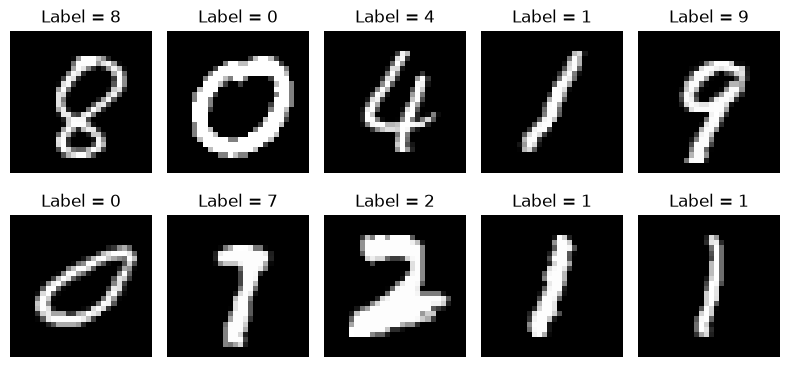

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# code du discriminateur
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


classifier = Classifier().to(device)
classifier

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [5]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )


train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4213
Epoch 2/3 - Loss = 0.1999
Epoch 3/3 - Loss = 0.1438


In [6]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.28%


In [7]:
# Auto encoder
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat


ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [9]:
# boucle d'apprentissage de l'auto-encodeur
#a la fin d'une regression on a une fonction d'activation. mais quand on fait un classifier a la fin on a pas de 
# fonction d'activation.
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)


def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )


train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0659
Epoch 2/5 - Loss = 0.0527
Epoch 3/5 - Loss = 0.0498
Epoch 4/5 - Loss = 0.0472
Epoch 5/5 - Loss = 0.0454


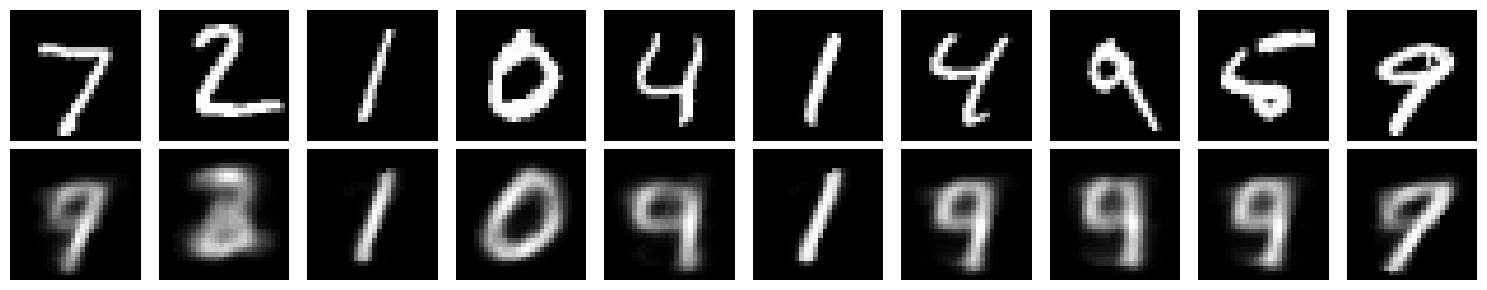

In [10]:
# tester le auto encodeur
# comparer 10 images originales avec leurs reconstructions par l’auto-encodeur entraîné
ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show()

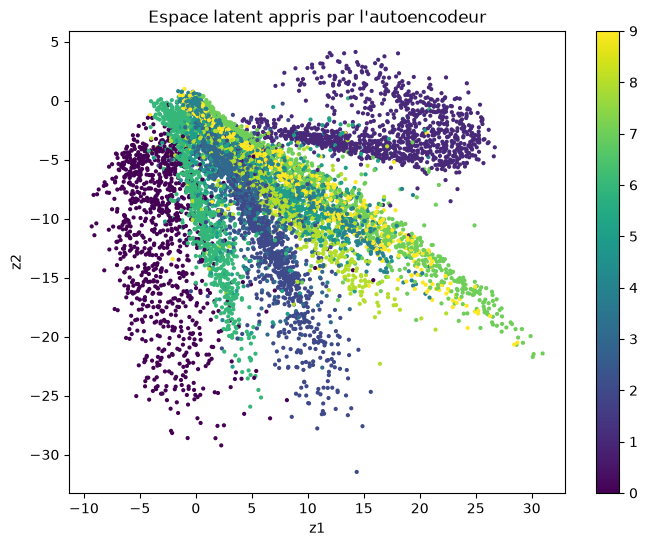

In [11]:
# explorer l'espace latent
    # on va prendre une image 28x28 pour le representer par un point dans l'espace latent
    # si les images sont mieux structurer dans l'espace latent, chaque type d'image vont former un cluster.
ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

In [ ]:
# cet espace latent n'est pas toujours pas très bien organiser car il va toujours faire la confusion entre les
# nombres

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt


class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        # Image 28 × 28 -> représentation intermédiaire
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
        )

        # Paramètres de la distribution latente q(z | x)
        self.fc_mu = nn.Linear(32, latent_dim)
        self.fc_logvar = nn.Linear(32, latent_dim)

        # Point latent -> image reconstruite
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + epsilon * std

    def decode(self, z):
        logits = self.decoder(z)
        return torch.sigmoid(logits).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

Le VAE optimise deux objectifs en même temps : reconstruire l’image et organiser l’espace latent
autour d’une loi normale \(\mathcal N(0,I)\).

In [13]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    # Erreur de reconstruction, additionnée sur les pixels
    reconstruction = F.binary_cross_entropy(
        x_hat, x, reduction="sum"
    )

    # Écart entre q(z | x) et la loi normale N(0, I)
    kl = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    # Moyenne par image pour rendre les valeurs affichées lisibles
    batch_size = x.size(0)
    return (
        (reconstruction + beta * kl) / batch_size,
        reconstruction / batch_size,
        kl / batch_size,
    )

In [14]:
vae = VAE(latent_dim=2).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)


def train_vae(model, loader, epochs=5):
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_reconstruction = 0.0
        total_kl = 0.0
        total_images = 0

        for x, _ in loader:
            x = x.to(device)

            optimizer.zero_grad()
            x_hat, mu, logvar = model(x)
            loss, reconstruction, kl = vae_loss(
                x_hat, x, mu, logvar
            )

            loss.backward()
            optimizer.step()

            batch_size = x.size(0)
            total_loss += loss.item() * batch_size
            total_reconstruction += reconstruction.item() * batch_size
            total_kl += kl.item() * batch_size
            total_images += batch_size

        print(
            f"Époque {epoch + 1}/{epochs} | "
            f"Perte : {total_loss / total_images:.2f} | "
            f"Reconstruction : "
            f"{total_reconstruction / total_images:.2f} | "
            f"KL : {total_kl / total_images:.2f}"
        )


train_vae(vae, train_loader, epochs=5)

Époque 1/5 | Perte : 210.26 | Reconstruction : 207.34 | KL : 2.93
Époque 2/5 | Perte : 172.50 | Reconstruction : 167.97 | KL : 4.53
Époque 3/5 | Perte : 166.93 | Reconstruction : 162.07 | KL : 4.86
Époque 4/5 | Perte : 164.51 | Reconstruction : 159.52 | KL : 4.99
Époque 5/5 | Perte : 162.03 | Reconstruction : 156.87 | KL : 5.16


In [ ]:
#Générer de nouveaux chiffres
#Après l’entraînement, on n’a plus besoin d’une image d’entrée. On tire directement des points
#\(z\) dans la loi normale et on les passe au décodeur :

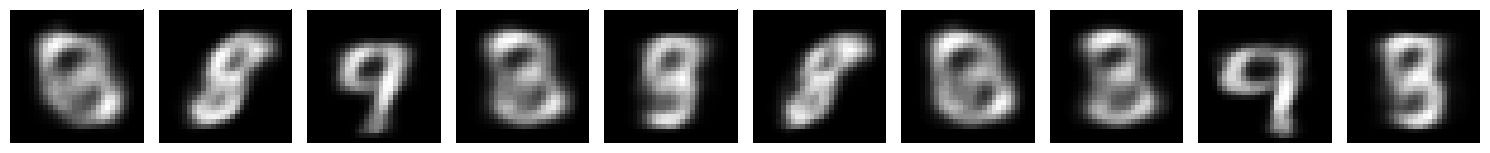

In [15]:
vae.eval()

with torch.no_grad():
    z = torch.randn(10, 2, device=device)
    images_generees = vae.decode(z).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for i, ax in enumerate(axes):
    ax.imshow(images_generees[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()

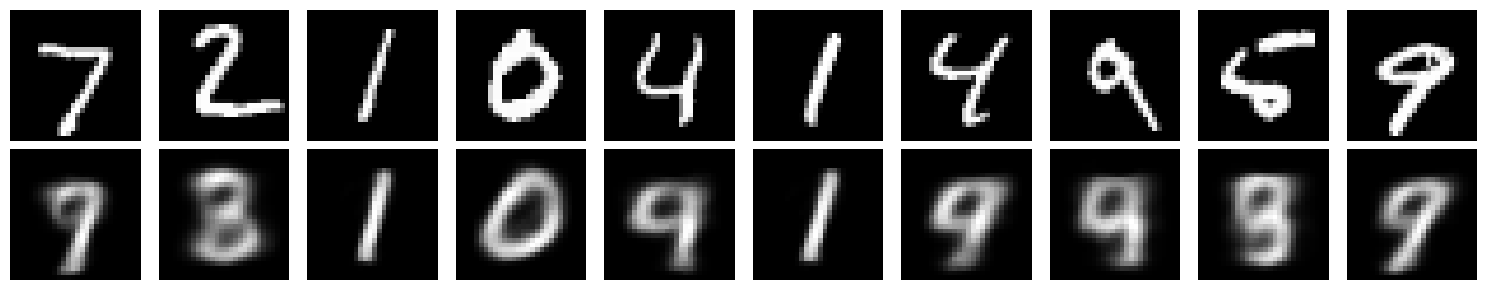

In [16]:
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, mu, logvar = vae(x)  # On récupère les images reconstruites

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show()

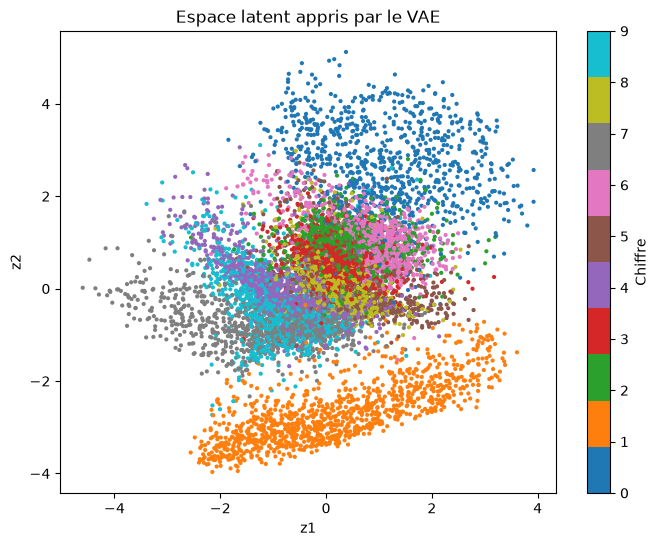

In [17]:
vae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)
        zs.append(mu.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4, cmap="tab10")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par le VAE")
plt.colorbar(scatter, ticks=range(10), label="Chiffre")
plt.show()

In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt


class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.latent_dim = latent_dim

        # Partie complétée : image MNIST -> 64 caractéristiques
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        # Paramètres de q(z | x)
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        # Partie visible sur ta capture
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar


vae = VAE(latent_dim=2).to(device)
print(vae)

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [ ]:
#2. Perte et entraînement
#La perte de reconstruction et la perte KL sont toutes les deux additionnées sur le lot. 
#Pour l’affichage, on divise ensuite les totaux par le nombre d’images traitées.
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss


vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)


def train_vae(model, loader, epochs=20, beta=1.0):
    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        total_rec = 0.0
        total_kl = 0.0
        total_images = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)
            loss, rec_loss, kl_loss = vae_loss(
                x_hat, x, mu, logvar, beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec_loss.item()
            total_kl += kl_loss.item()
            total_images += x.size(0)

        print(
            f"Époque {epoch + 1:2d}/{epochs} | "
            f"Perte : {total_loss / total_images:.2f} | "
            f"Reconstruction : {total_rec / total_images:.2f} | "
            f"KL : {total_kl / total_images:.2f}"
        )


train_vae(vae, train_loader, epochs=20, beta=1.0)

Époque  1/20 | Perte : 195.92 | Reconstruction : 192.24 | KL : 3.68
Époque  2/20 | Perte : 166.95 | Reconstruction : 162.01 | KL : 4.93
Époque  3/20 | Perte : 161.13 | Reconstruction : 155.90 | KL : 5.22
Époque  4/20 | Perte : 157.88 | Reconstruction : 152.52 | KL : 5.36
Époque  5/20 | Perte : 155.72 | Reconstruction : 150.23 | KL : 5.49
Époque  6/20 | Perte : 153.70 | Reconstruction : 148.07 | KL : 5.64
Époque  7/20 | Perte : 152.20 | Reconstruction : 146.46 | KL : 5.74
Époque  8/20 | Perte : 150.89 | Reconstruction : 145.07 | KL : 5.82
Époque  9/20 | Perte : 149.82 | Reconstruction : 143.95 | KL : 5.87
Époque 10/20 | Perte : 149.05 | Reconstruction : 143.11 | KL : 5.94
Époque 11/20 | Perte : 148.14 | Reconstruction : 142.14 | KL : 6.00
Époque 12/20 | Perte : 147.44 | Reconstruction : 141.40 | KL : 6.04
Époque 13/20 | Perte : 146.98 | Reconstruction : 140.88 | KL : 6.09
Époque 14/20 | Perte : 146.38 | Reconstruction : 140.26 | KL : 6.12
Époque 15/20 | Perte : 145.95 | Reconstruction :

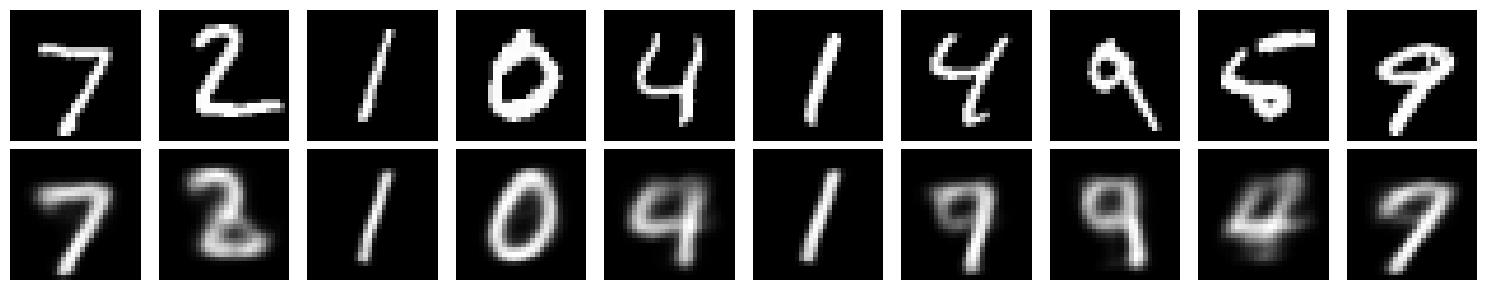

In [28]:
#3. Comparer originaux et reconstructions
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show()

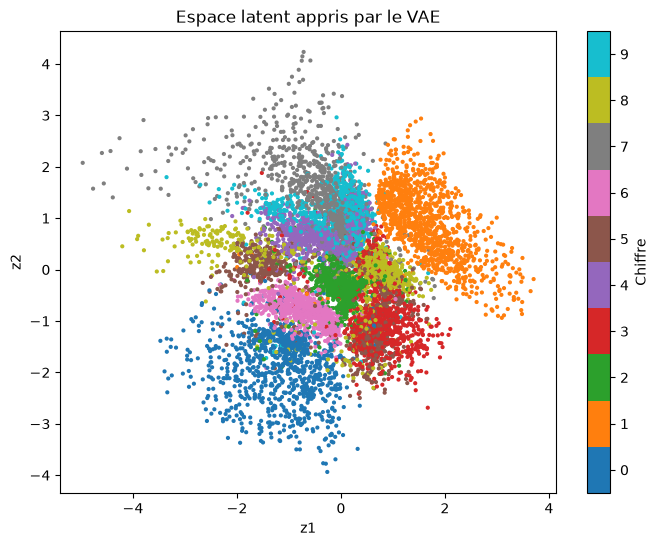

In [29]:
#4. Visualiser l’espace latent
#Chaque point est une image du jeu de test. 
#On utilise mu comme coordonnées stables ; les étiquettes servent seulement à colorer le graphique.
vae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        mu, logvar = vae.encode(x)

        zs.append(mu.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    Z[:, 0], Z[:, 1],
    c=Y, s=4, cmap="tab10",
    vmin=-0.5, vmax=9.5
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par le VAE")
plt.colorbar(scatter, ticks=range(10), label="Chiffre")
plt.show()

In [ ]:
# Generative Adverserial Networks
    #genere une image(generateur)
    #est ce que c'est bon ou pas(discriminateur)
    #nb: apprendre au generateur à faire des choses qui vont satisfaire le discriminateur
    # Ex: Supposons que vous voulez créer un modele qui génère des personnes
    # On a besoin d'un dataset dans lequel. il ya des photos la ou il y a des personnes et il ya des photos ou 
    # il y a des objets, des animaux etc..
    # ce dataset etique on on generer une image. est ce que c'est une personne ou non?
    # apprendre au generateur à generer des personnes
    # exemple de site: thispersondoesnotexist
    
    

In [ ]:
# Diffusion Models(DF)
    #Un modele generatif qui apprend progressivement le bruit pour construire des données réaliste
# Après l'apprentissage, il peut générer de nouvelles données en partant d'un bruit aléatoire.
# exemple de site: stable diffusion

In [ ]:
# Autoregressive Models(ARM)
    #Un model auto-regressif est un modèle generatif qui produit une donnée etape par étape, en prédisant
    # le prochain élément à partir des éléments précédents.
    # generer un element en fonction de ce qu'il a généré auparavant.

In [ ]:
# Flow-based Models(FBM)
    # un modèle à flot est un modèle generatif qui apprend une transformation reversible et continue entre une
    # distribution simple(ex: gaussienne) et une distribution données, ce qui permet de generer et de reconstruire
    #les données

In [ ]:
# Energy based Model(EBM)
    #Un modèle basé sur l'energie est un modele generatif qui apprend une fonction d'energie qui attribue une energie
    #faible aux données réalistes et une energie élévées aux données non réeéliste.
    # Les nouvelles données sont générées en recherchant des états faible d'energie.
    # ex: modele piloté par la physique PINN
    # le probleme actuelle des modèles génératif: si vous demander à un modèle de vous générer une voiture 
    # qui vole et après il vous génère la voiture qui vole
    # Mais est ce que c'est normale? une voiture peut elle voler? Non
    # mais le modele n'a aucune idée sur les lois de la physique. EBM va apporter une information sur la 
    # physique
    